# Quick EDA

## Datenimport

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import csv


data_dir = Path("data")

antrieb = pd.read_csv(data_dir / "Antriebsarten nach Gemeinden.csv", encoding="latin1", sep=",", index_col=None, quoting=csv.QUOTE_NONE)
einwohner = pd.read_csv(data_dir / "Einwohner nach Gemeinden.csv", encoding="latin1", index_col=None, quoting=csv.QUOTE_NONE)
geo = pd.read_excel(data_dir / "Geographische_Kennzahlen.xlsx", index_col=None, )


## Antrieb

### Übersicht

In [52]:
# Unnötige Zahlen und Zeichen entfernt
antrieb.columns = antrieb.columns.str.replace('"', "", regex=False)
antrieb = antrieb.replace('"', "", regex=True)
antrieb["Gemeinde"] = antrieb["Gemeinde"].str.replace(r"^\d+\s*", "", regex=True)
print(antrieb.head())



          Gemeinde Fahrzeuggruppe                         Treibstoff  2010  \
0  Aeugst am Albis  Personenwagen                             Benzin   863   
1  Aeugst am Albis  Personenwagen                             Diesel   175   
2  Aeugst am Albis  Personenwagen   Benzin-elektrisch: Normal-Hybrid     3   
3  Aeugst am Albis  Personenwagen  Benzin-elektrisch: Plug-in-Hybrid     0   
4  Aeugst am Albis  Personenwagen   Diesel-elektrisch: Normal-Hybrid     0   

   2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  \
0   881   891   881   856   845   822   815   816   809   804   789   778   
1   204   229   250   276   288   306   316   318   326   329   321   311   
2     5     7    11    13    13    18    16    20    22    30    43    49   
3     0     0     0     0     0     1     2     7     7    12    20    23   
4     0     1     1     0     0     0     2     2     3     2     5     5   

   2023 2024  
0   774  724  
1   292  287  
2    57   74  
3    26 

### Spalten und Zeilen

In [53]:
row, col = antrieb.shape
print(f"Zeilenanzahl, {row}")
print(f"Spaltenanzahl, {col}")

Zeilenanzahl, 164087
Spaltenanzahl, 18


### Fehlende Werte

In [54]:
antrieb.isna().sum()

Gemeinde          0
Fahrzeuggruppe    0
Treibstoff        0
2010              0
2011              0
2012              0
2013              0
2014              0
2015              0
2016              0
2017              0
2018              0
2019              0
2020              0
2021              0
2022              0
2023              0
2024              0
dtype: int64

### Lagemasse und Infos

In [55]:
antrieb.describe()

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
count,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000,164087.000000
mean,34.916441,35.720520,36.541664,37.123197,37.722147,38.388788,39.015882,39.506664,39.918269,40.248106,40.783926,41.443094,41.676294,42.181544
std,492.983725,488.498302,484.822365,478.492017,473.769713,471.871313,470.050430,467.444586,465.370175,460.422331,456.398404,448.738626,436.468538,427.695502
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,109599.000000,106308.000000,103312.000000,99617.000000,96517.000000,94313.000000,92172.000000,90270.000000,89420.000000,87542.000000,86493.000000,83914.000000,81298.000000,79168.000000


### Korrelation

<Axes: >

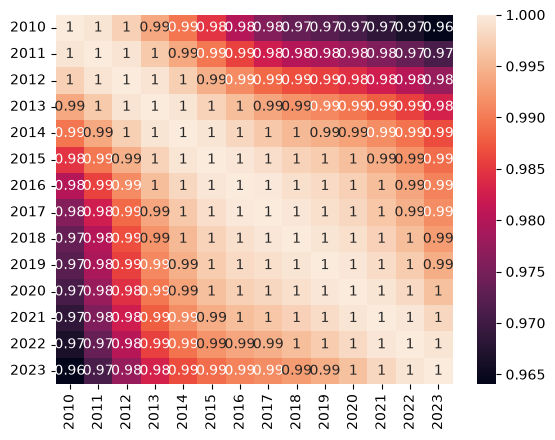

In [56]:
sns.heatmap(antrieb.corr(numeric_only=True), annot=True)

## Einwohner

### Übersicht

In [57]:
einwohner.columns = einwohner.columns.str.replace('"', "", regex=False)
einwohner = einwohner.replace('"', "", regex = True)
einwohner = einwohner.rename(columns={"Kanton (-) / Bezirk (>>) / Gemeinde (......)": "Gemeinde"})
einwohner["Gemeinde"] = einwohner["Gemeinde"].str.replace(r"^[.\s]*\d+\s*", "", regex=True)
einwohner["Jahr"] = pd.to_numeric(einwohner["Jahr"], errors="coerce")
einwohner["Staatsangehörigkeit - Total"] = pd.to_numeric(einwohner["Staatsangehörigkeit - Total"], errors="coerce")
einwohner = einwohner[einwohner["Gemeinde"].isin(antrieb["Gemeinde"])].copy()

print(einwohner.head())


   Jahr            Gemeinde           Bevölkerungstyp  \
3  2010     Aeugst am Albis  Ständige Wohnbevölkerung   
4  2010  Affoltern am Albis  Ständige Wohnbevölkerung   
5  2010          Bonstetten  Ständige Wohnbevölkerung   
6  2010     Hausen am Albis  Ständige Wohnbevölkerung   
7  2010            Hedingen  Ständige Wohnbevölkerung   

   Staatsangehörigkeit - Total  
3                         1824  
4                        11091  
5                         5159  
6                         3360  
7                         3410  


### Zeilen und Spalten

In [71]:
row_einw, col_einw = einwohner.shape
print(f"Zeilenanzahl, {row_einw}")
print(f"Spaltenanzahl, {col_einw}")

Zeilenanzahl, 33792
Spaltenanzahl, 4


### Fehlende Werte

In [59]:
einwohner.isna().sum()

Jahr                           0
Gemeinde                       0
Bevölkerungstyp                0
Staatsangehörigkeit - Total    0
dtype: int64

### Lagemasse und Infos

In [60]:
einwohner[["Jahr", "Staatsangehörigkeit - Total"]].describe()

,Jahr,Staatsangehörigkeit - Total
count,33792.00000,33792.000000
mean,2017.50000,4016.409594
std,4.60984,12792.380986
min,2010.00000,28.000000
25%,2013.75000,750.000000
50%,2017.50000,1627.000000
75%,2021.25000,3898.000000
max,2025.00000,440935.000000


### Korrelation

In [69]:
einwohner_wide = einwohner.pivot_table(
    index="Gemeinde",
    columns="Jahr",
    values="Staatsangehörigkeit - Total",
    aggfunc="sum"
)

print(einwohner_wide.head())

Jahr        2010   2011   2012   2013   2014   2015   2016   2017   2018  \
Gemeinde                                                                   
Aadorf      8084   8281   8418   8473   8599   8794   8865   8885   9037   
Aarau      19497  19840  20103  20185  20445  20710  21036  21268  21506   
Aarberg     4088   4085   4182   4273   4422   4529   4527   4581   4628   
Aarburg     7000   7065   7193   7233   7567   7723   7854   8068   8197   
Aarwangen   4180   4196   4229   4253   4312   4408   4518   4514   4561   

Jahr        2019   2020   2021   2022   2023   2024   2025  
Gemeinde                                                    
Aadorf      9047   9216   9359   9422   9485   9800   9924  
Aarau      21773  21726  21773  21807  22290  22710  22932  
Aarberg     4632   4626   4600   4629   4648   4620   4601  
Aarburg     8376   8577   8562   8746   8891   8917   9040  
Aarwangen   4620   4638   4715   4793   4772   4813   4873  


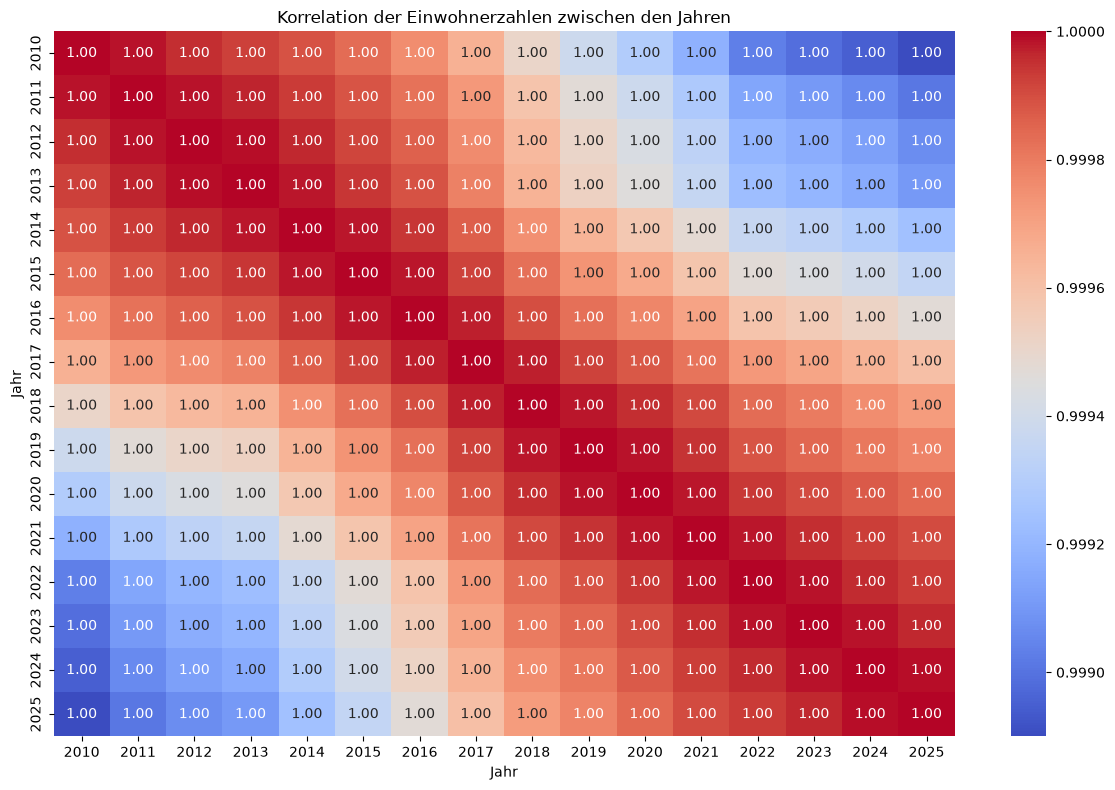

In [70]:
plt.figure(figsize=(12, 8))
sns.heatmap(einwohner_wide.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korrelation der Einwohnerzahlen zwischen den Jahren")
plt.tight_layout()

## Geographische Kennzahlen

### Übersicht

In [62]:
geo.sort_values(by=["KTNAME", "AREA_HA"], inplace=True)
geo = geo[geo["GDENAME"].isin(antrieb["Gemeinde"])]
print(geo.head())


     GDEHISTID  GDENR        GDENAME  AREA_HA  KTNR  KTNAME  BEZNR  \
659      12783   4137  Leimbach (AG)      115    19  Aargau   1905   
65       10338   4288       Wiliberg      117    19  Aargau   1910   
213      11472   4193        Brunegg      155    19  Aargau   1907   
841      13669   4084      Islisberg      166    19  Aargau   1903   
491      12277   4026     Ennetbaden      211    19  Aargau   1902   

               BEZNAME  
659        Bezirk Kulm  
65     Bezirk Zofingen  
213    Bezirk Lenzburg  
841  Bezirk Bremgarten  
491       Bezirk Baden  


### Zeilen und Spalten

In [63]:
row_geo, col_geo = geo.shape
print(f"Zeilenanzahl, {row_geo}")
print(f"Spaltenanzahl, {col_geo}")

Zeilenanzahl, 2107
Spaltenanzahl, 8


### Fehlende Werte

In [64]:
geo.isna().sum()

GDEHISTID    0
GDENR        0
GDENAME      0
AREA_HA      0
KTNR         0
KTNAME       0
BEZNR        0
BEZNAME      0
dtype: int64

### Lagemasse und Infos

In [65]:
geo[["AREA_HA"]].describe()

,AREA_HA
count,2107.000000
mean,1895.317513
std,3410.668814
min,31.000000
25%,450.000000
50%,859.000000
75%,1751.000000
max,43861.000000


### Korrelation

<Axes: >

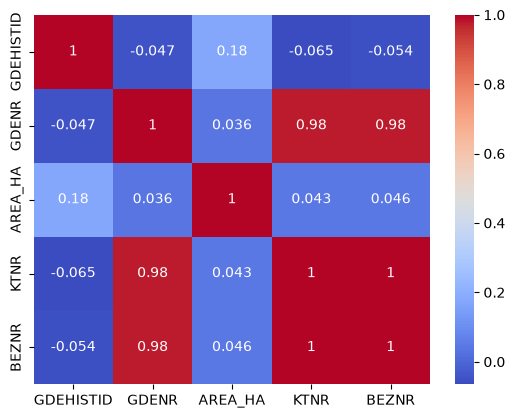

In [66]:
sns.heatmap(geo.corr(numeric_only=True), annot=True, cmap="coolwarm")

## Beurteilung

In [72]:
print(antrieb["Gemeinde"].nunique())
print(einwohner["Gemeinde"].nunique())
print(geo["GDENAME"].nunique())

2131
2112
2106


In [ ]:
# In antrieb vorhanden, aber nicht in einwohner
set(antrieb["Gemeinde"]) - set(einwohner["Kanton"])

{'Astano',
 'Auboranges',
 'Bedigliora',
 'Bodio',
 'Chapelle (Glâne)',
 'Curio',
 'Ecublens (FR)',
 'Enges',
 'Grolley',
 'Hauterive (NE)',
 'Honau',
 'La Tène',
 'Miglieglia',
 'Montet (Glâne)',
 'Novaggio',
 'Ponthaux',
 'Prato (Leventina)',
 'Saint-Blaise',
 'Tschiertschen-Praden'}

In [ ]:
# In antrieb vorhanden, aber nicht in geo
set(antrieb["Gemeinde"]) - set(geo["GDENAME"])

{'Astano',
 'Auboranges',
 'Bedigliora',
 'Bodio',
 'Chapelle (Glâne)',
 'Curio',
 'Ecublens (FR)',
 'Enges',
 'Fétigny',
 'Grolley',
 'Halten',
 'Hauterive (NE)',
 'Honau',
 'La Tène',
 'Miglieglia',
 'Montet (Glâne)',
 'Ménières',
 'Novaggio',
 'Oekingen',
 'Ponthaux',
 'Prato (Leventina)',
 'Saint-Blaise',
 'Tschiertschen-Praden',
 'Ulmiz',
 'Villnachern'}

Die drei Datensätze weisen unterschiedliche Gemeindezahlen auf (Antrieb: 2131, Einwohner: 2112, Geo: 2106). Eine gemeinsame Analyse erscheint grundsätzlich möglich, jedoch müssen vor der Zusammenführung die fehlenden Gemeinden, ihre Kantonszugehörigkeit sowie mögliche Gemeindefusionen und unterschiedliche Datenstände überprüft werden.